# 01 · Data audit
Source: Sakar & Kastro (2018), [Online Shoppers Purchasing Intention Dataset](https://doi.org/10.24432/C5F88Q), UCI, CC BY 4.0. See `data/README.md`.

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

root = Path.cwd()
if not (root / "data").is_dir():
    root = root.parent

df = pd.read_csv(root / "data/raw/online_shoppers_intention.csv")
print(f"{df.shape[0]:,} rows, {df.shape[1]} columns ({df.shape[1] - 1} inputs and Revenue)")
df.head()

12,330 rows, 18 columns (17 inputs and Revenue)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## Types and missing values

In [8]:
pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()})

,dtype,missing
Administrative,int64,0
Administrative_Duration,float64,0
Informational,int64,0
Informational_Duration,float64,0
ProductRelated,int64,0
ProductRelated_Duration,float64,0
BounceRates,float64,0
ExitRates,float64,0
PageValues,float64,0
SpecialDay,float64,0


## Duplicates

In [9]:
features = df.columns.drop("Revenue").tolist()
conflicting_groups = df.groupby(features, dropna=False)["Revenue"].nunique().gt(1).sum()
pd.Series({
    "Additional exact duplicates": df.duplicated().sum(),
    "Identical-input groups with conflicting targets": conflicting_groups,
})

Additional exact duplicates                        125
Identical-input groups with conflicting targets      0
dtype: int64

## Purchase counts

In [10]:
target_counts = df["Revenue"].value_counts().sort_index()
pd.DataFrame({"sessions": target_counts, "percentage": (target_counts / len(df) * 100).round(2)})

,sessions,percentage
Revenue,,
False,10422,84.53
True,1908,15.47


## Numeric values and outliers

In [11]:
numeric_features = [
    "Administrative", "Administrative_Duration", "Informational",
    "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay",
]
df[numeric_features].describe(percentiles=[0.5, 0.95, 0.99]).T

,count,mean,std,min,50%,95%,99%,max
Administrative,12330.0,2.315166,3.321784,0.0,1.000000,9.000000,14.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,7.500000,348.266369,830.587041,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,3.000000,6.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,195.000000,716.390000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,18.000000,109.000000,221.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,598.936905,4300.289077,8701.142697,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.003112,0.200000,0.200000,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.025156,0.200000,0.200000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,38.160528,85.498490,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.600000,1.000000,1.000000


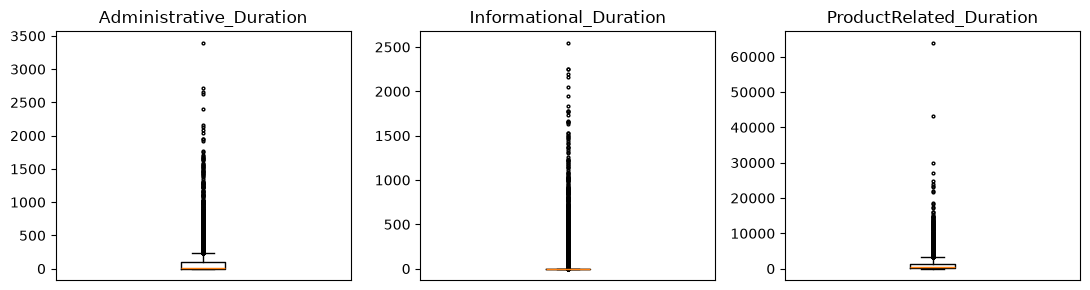

In [12]:
duration_columns = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration"]
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, column in zip(axes, duration_columns):
    ax.boxplot(df[column], flierprops={"markersize": 2})
    ax.set(title=column, xticks=[])
fig.tight_layout()
plt.show()

## Findings

- The dataset has 12,330 sessions, 17 inputs and no missing values.
- There are 125 repeated rows.
- Only 15.47% of sessions led to a purchase.
- Most durations are short, but a few are much longer. `ProductRelated_Duration` goes up to about 63,974.